In [1]:
import os, glob
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dict_keys(['__header__', '__version__', '__globals__', 'ETdata', 'results', 'fpData'])


In [ ]:
l_label = np.array([1,2,3,4,5,6])
d_label = {
    1: "Fixation",
    2: "Saccade",
    3: "Post-saccadic oscillation",
    4: "mooth pursuit",
    5: "Blink",
    6: "Undefined",
    }
sigma_threshold_scale = 0.01




def calc_saccade(data_mat, sigma_threshold_scale=0.01, show_plot=False):
    # データ取り込み
    sampFreq = data_mat["ETdata"]["sampFreq"][0][0][0][0]
    viewDist = data_mat["ETdata"]["viewDist"][0][0][0][0]
    screenDim = data_mat["ETdata"]["screenDim"][0][0][0]
    screenRes = data_mat["ETdata"]["screenRes"][0][0][0]

    x_center, y_center = (screenRes-1)/2
    time_bin = 1/sampFreq

    df_data = pd.DataFrame(data_mat["ETdata"]["pos"][0][0])
    df_data[0] = (1/sampFreq)*df_data.index 
    df_data[5] = df_data[5].astype('int64')

    # ディスプレイの中心座標に
    df_data["pos_x"] = df_data[3] - x_center
    df_data["pos_y"] = df_data[4] - y_center

    # 角度に変換
    df_data["degree"] = calc_deg(df_data["pos_x"], df_data["pos_y"], screenRes, screenDim, viewDist)
    # 角速度に変換
    df_data["mov_deg"] = df_data["degree"].diff()/time_bin
    # 角加速度に変換
    df_data["acc_deg"] = df_data["mov_deg"].diff()/time_bin

    # 角加速度の大きさを見たいので絶対値に変換
    df_data["acc_deg_abs"] = df_data["acc_deg"].abs()

    # 5フレーム分で移動平均。移動平均は前5フレーム分
    moving_average_window = 10
    df_data["acc_deg_abs_moving_avg"] = df_data["acc_deg_abs"].rolling(moving_average_window).mean() # 前の3つとの平均。 [4:-2]

    # 閾値作成のため、標準偏差を計算
    processed_sigma = df_data["acc_deg_abs_moving_avg"][2:-2].std()
    processed_mean = df_data["acc_deg_abs_moving_avg"][2:-2].mean()
    processed_threshold = processed_sigma*sigma_threshold_scale + processed_mean
    # 標準偏差に固定倍率をかけた値を閾値に、それ以上をサッカード。
    df_data["saccade_estimate"] = df_data["acc_deg_abs_moving_avg"]>(processed_threshold)
    # display(df_data.dtypes)
    # df_data["saccade_estimate"][df_data["acc_deg_abs_moving_avg"].isnull()] = np.nan

    
    if show_plot:
        for i_label in l_label:
            df_data_slice = df_data.iloc[2:-2][df_data.iloc[2:-2][5]==i_label].copy()
            plt.scatter(df_data_slice[0], df_data_slice["acc_deg_abs"], label=d_label[i_label], s=2)
        plt.plot(df_data[0].iloc[2:-2], df_data["acc_deg_abs"].iloc[2:-2], zorder=0)
        plt.plot(
            df_data[0].iloc[moving_average_window:-2], 
            df_data["acc_deg_abs_moving_avg"].iloc[moving_average_window:-2], 
            zorder=0, c="b", marker="o", markersize=2)
        
        sigma_range = 0.15
        plt.axhline(processed_threshold)
        # plt.ylim(0, sigma*sigma_range)
        # plt.xlim(show_range_start, show_range_end)
        
        plt.title(os.path.basename(dirs_datas_RA[0]).replace(".mat",""))
        plt.legend()
        # plt.save()
        plt.show()


    
    np_estimate = df_data["saccade_estimate"].to_numpy()
    np_estimate = np_estimate.astype(object)
    np_null = df_data["acc_deg_abs_moving_avg"].isnull().to_numpy()
    np_null = np_null.astype(object)
    np_null[-2:] = True
    np_null = np_null.astype(bool)
    np_estimate[np_null] = np.nan
    # np_null = np_null.astype(object)
    # np_null[-2:] = np.nan
    # print(np_null)

    # 回答
    np_ans = (df_data[5]==2).to_numpy()

    return np_estimate, np_ans


def calc_deg(x_mov_pix, y_mov_pix, screenRes, screenDim, viewDist):
    dist_x_mov_m = (x_mov_pix/screenRes[0]) * screenDim[0]
    dist_y_mov_m = (y_mov_pix/screenRes[1]) * screenDim[1]
    dist_mov_m = ((dist_x_mov_m**2)+(dist_y_mov_m**2))**(1/2)
    return np.degrees(np.arctan2(dist_mov_m, viewDist))


def cacl_correct(np_estimate, np_ans):
    TP = (np_estimate & np_ans).sum()
    FN = (~np_estimate & np_ans).sum()
    FP = (np_estimate & ~np_ans).sum()
    TN = (~np_estimate & ~np_ans).sum()
    # print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")
    return TP, FN, FP, TN

def remove_nan(np_estimate, np_ans):
    np_estimate_removed = np_estimate[~pd.isna(np_estimate)].astype(bool)
    np_ans_removed      = np_ans[~pd.isna(np_estimate)].astype(bool)
    return np_estimate_removed, np_ans_removed

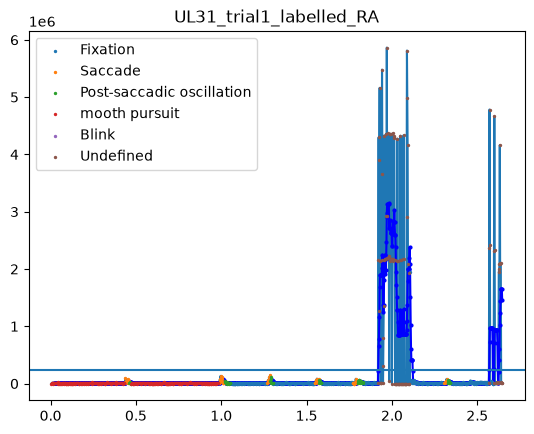

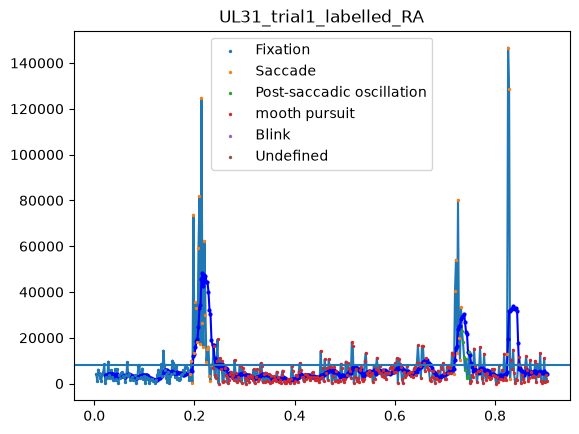

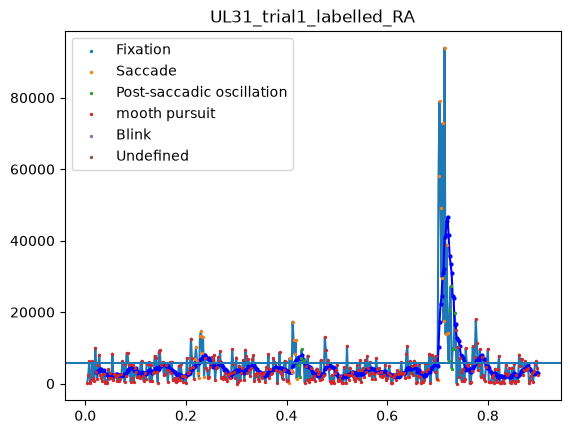

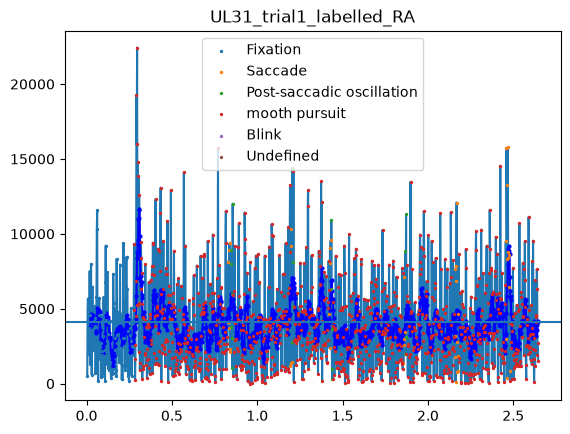

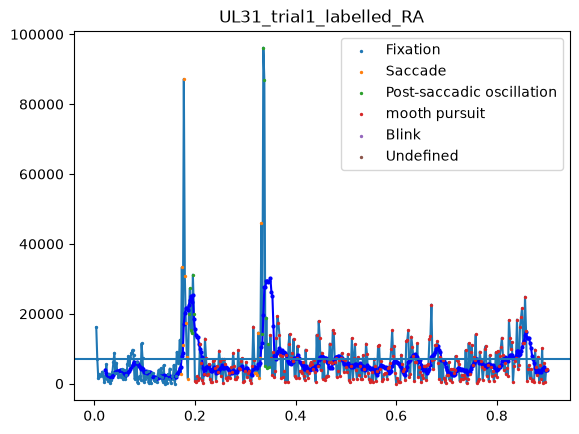

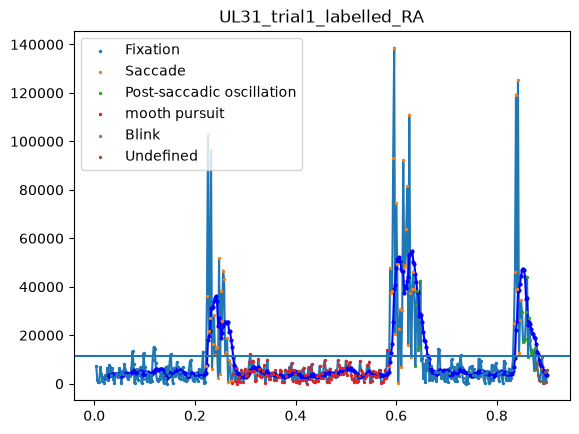

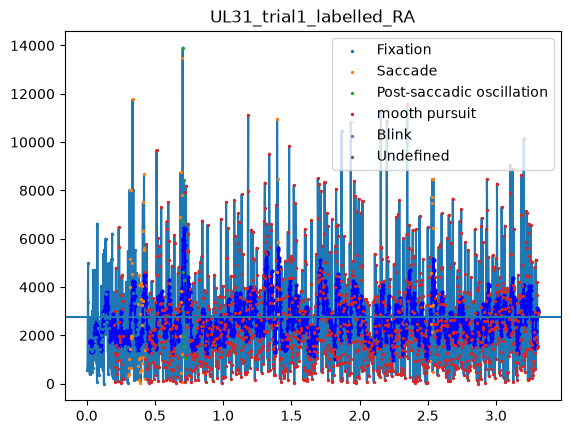

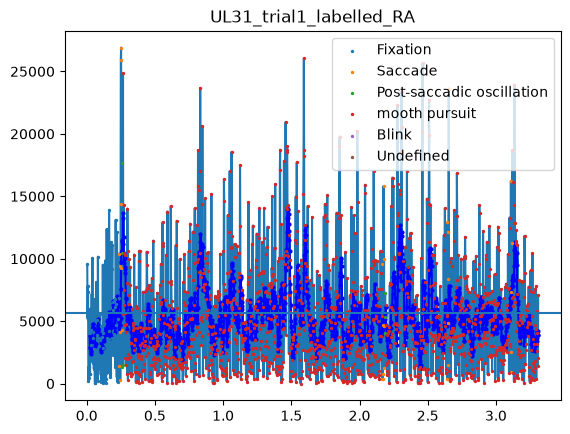

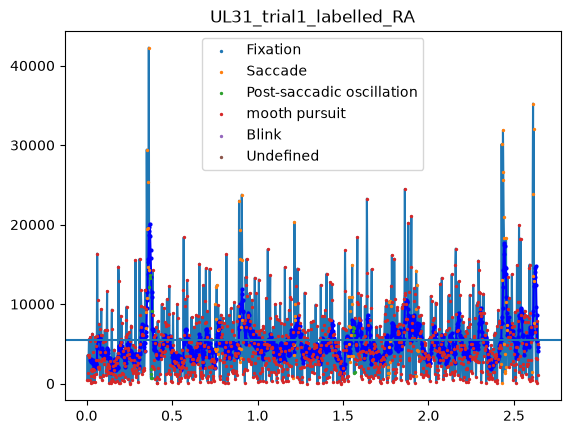

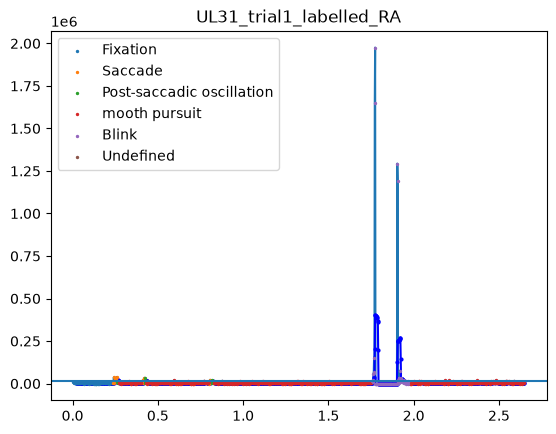

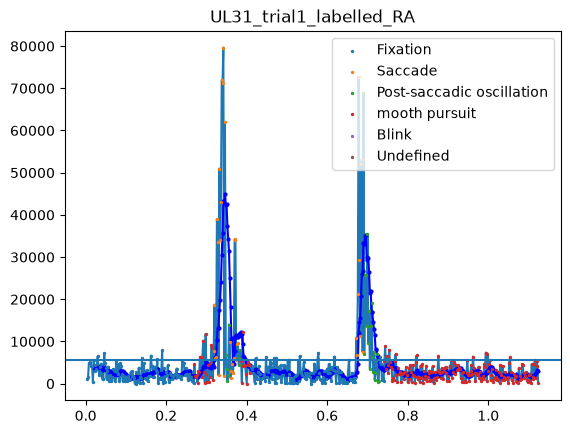

[[   0   78  132 1103]
 [  29    5   34  374]
 [  23    7   40  370]
 [  35   13  484  781]
 [   8    7  104  321]
 [  54    6   31  349]
 [  42   28  600  975]
 [  10   21  587 1027]
 [  65   28  368  850]
 [   4   23   41 1246]
 [  29    6   33  484]]
[np.float64(0.0), np.float64(0.8529411764705882), np.float64(0.7666666666666667), np.float64(0.7291666666666666), np.float64(0.5333333333333333), np.float64(0.9), np.float64(0.6), np.float64(0.3225806451612903), np.float64(0.6989247311827957), np.float64(0.14814814814814814), np.float64(0.8285714285714286)]
[np.float64(0.8931174089068826), np.float64(0.9166666666666666), np.float64(0.9024390243902439), np.float64(0.6173913043478261), np.float64(0.7552941176470588), np.float64(0.9184210526315789), np.float64(0.6190476190476191), np.float64(0.6363073110285006), np.float64(0.6978653530377669), np.float64(0.9681429681429682), np.float64(0.9361702127659575)]


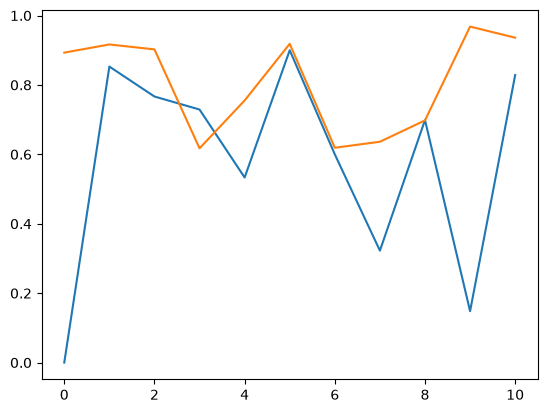

In [16]:
l_result = []
for dir_datas_RA in dirs_datas_RA:
    data_mat = scipy.io.loadmat(dir_datas_RA)
    np_estimate, np_ans = calc_saccade(data_mat, sigma_threshold_scale=0.15, show_plot=True)
    # print(type(result))
    # print(len(result))
    # print(~pd.isna(result))
    # print(result[~pd.isna(result)])
    # print(len(result[~pd.isna(result)]))

    # np_estimate = np_estimate[~pd.isna(np_estimate)].astype(bool)
    # np_ans = np_ans[~pd.isna(np_estimate)].astype(bool)
    # print(len(np_estimate))
    np_estimate, np_ans = remove_nan(np_estimate, np_ans)

    # print(np_estimate.dtype)
    # print(np_ans.dtype)
    # print(len(np_estimate))
    # print(len(np_ans))

    # print(np_estimate)
    # print(np_estimate&np_ans)

    TP, FN, FP, TN = cacl_correct(np_estimate, np_ans)
    l_result.append([TP, FN, FP, TN].copy())

    # break
print(np.array(l_result))


l_TP_rate = [i[0]/(i[0]+i[1]) for i in l_result]
l_TN_rate = [i[3]/(i[2]+i[3]) for i in l_result]
print(l_TP_rate)
print(l_TN_rate)
plt.plot(l_TP_rate)
plt.plot(l_TN_rate)
plt.show()

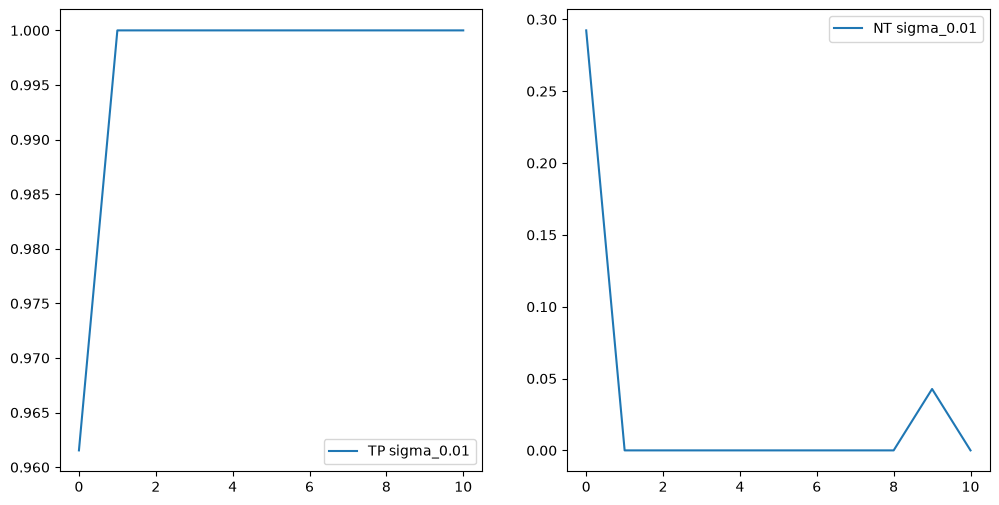

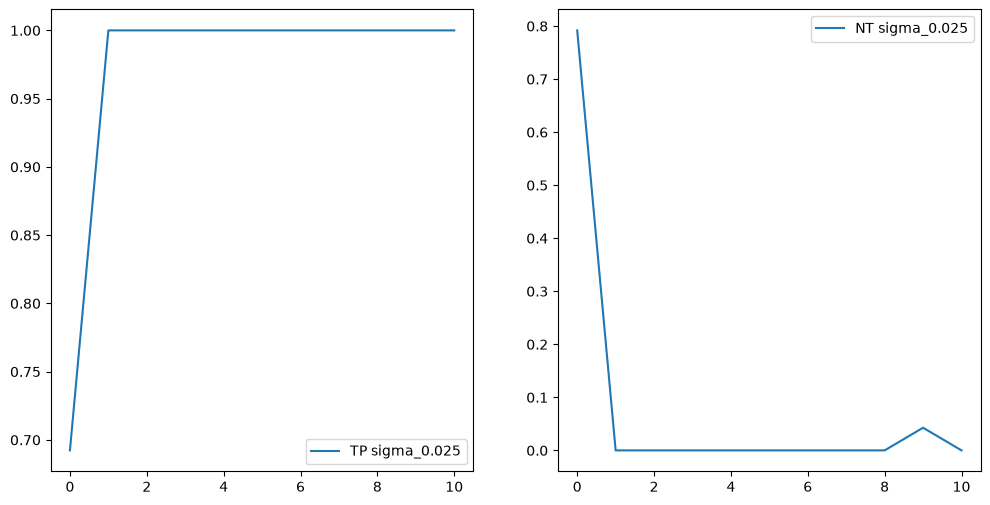

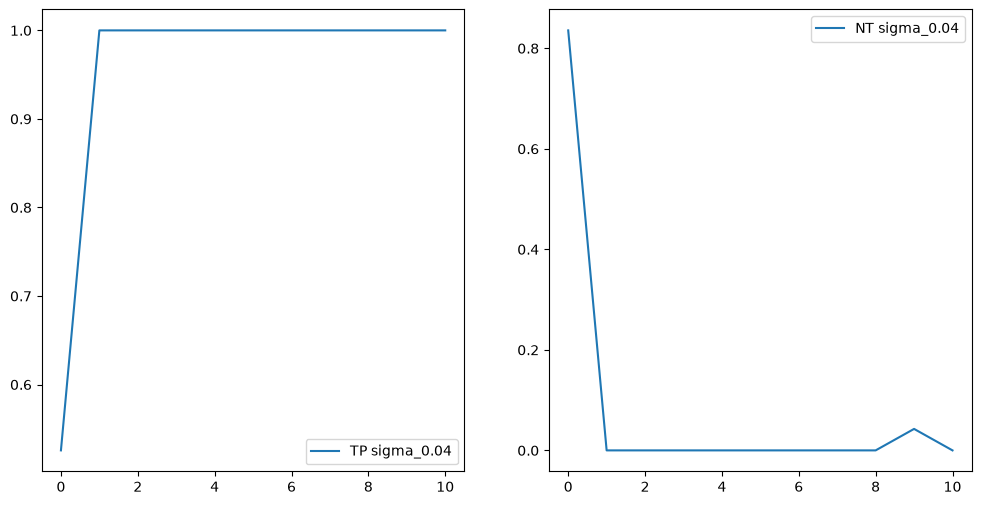

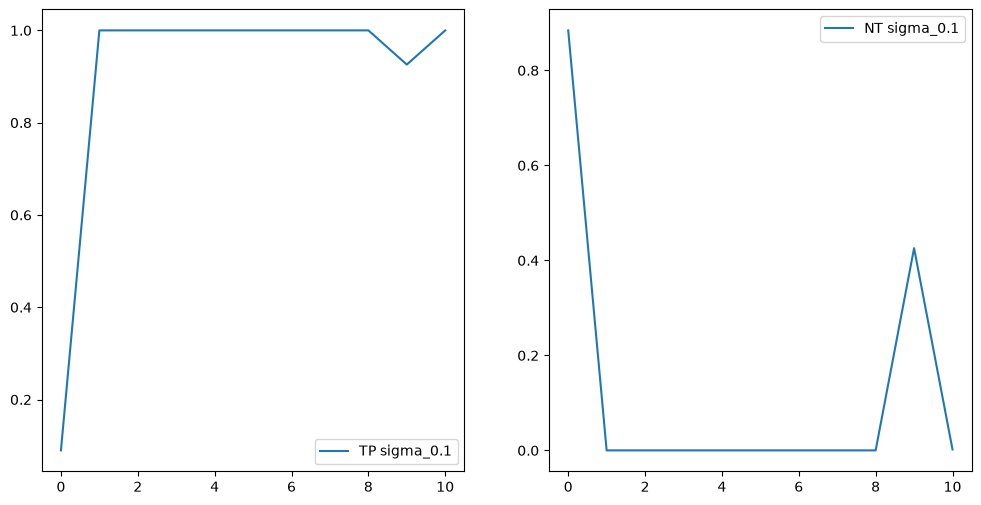

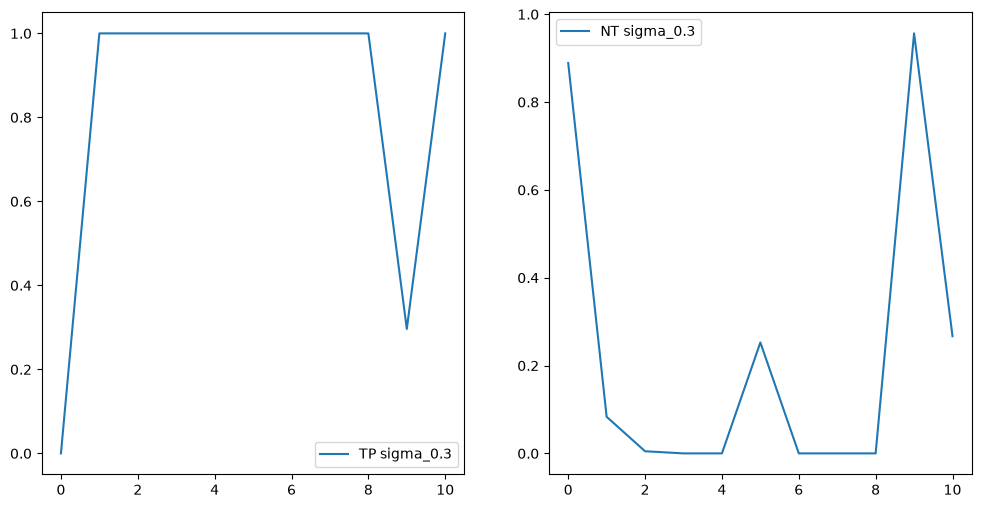

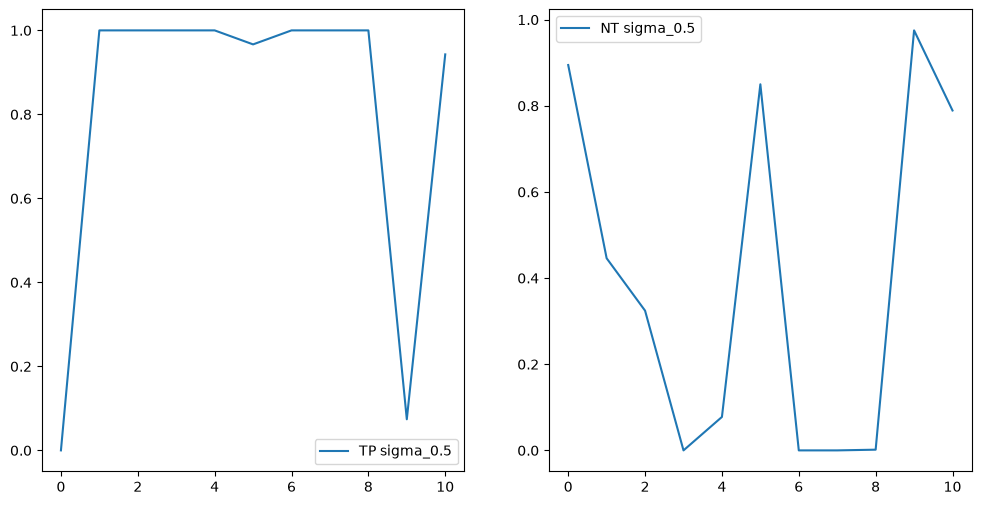

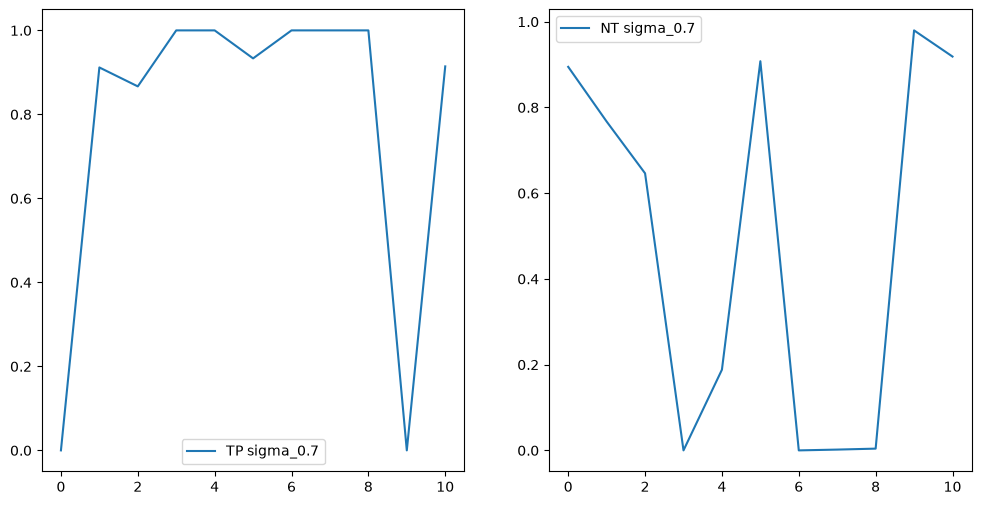

In [14]:

l_sigma_threshold_scale = [0.01, 0.025, 0.04, 0.1, 0.3, 0.5, 0.7]



for sigma_threshold_scale in l_sigma_threshold_scale:
    l_result = []
    for dir_datas_RA in dirs_datas_RA:
        data_mat = scipy.io.loadmat(dir_datas_RA)
        np_estimate, np_ans = calc_saccade(data_mat, sigma_threshold_scale=sigma_threshold_scale)
        np_estimate, np_ans = remove_nan(np_estimate, np_ans)
        TP, FN, FP, TN = cacl_correct(np_estimate, np_ans)
        l_result.append([TP, FN, FP, TN].copy())

    # print(np.array(l_result))

    fig, axes = plt.subplots(1,2, figsize=(12,6))
    l_TP_rate = [i[0]/(i[0]+i[1]) for i in l_result]
    l_TN_rate = [i[3]/(i[2]+i[3]) for i in l_result]
    # print(l_TP_rate)
    # print(l_TN_rate)
    axes[0].plot(l_TP_rate, label="TP sigma_{:.3}".format(sigma_threshold_scale))
    axes[0].legend()
    axes[1].plot(l_TN_rate, label="NT sigma_{:.3}".format(sigma_threshold_scale))
    axes[1].legend()
    plt.show()